Start with importing some libraries and defining various functions regarding the normal distribution, which we use throughout this notebook

In [2]:
import samplers, amoc_model
import numpy as np
import importlib
import matplotlib.pyplot as plt

def normal_dist(x,mu=0, sigma=1):
    return (1/np.sqrt(2*np.pi*sigma**2)) * np.exp(-((x-mu)**2)/(2*sigma**2))

def log_normal(x,mu=0,sigma=1):
    return np.sum(-0.5*np.log(2*np.pi*sigma**2) -((x-mu)**2)/(2*sigma**2))

def grad_log_normal(x, mu=0, sigma=1):
    return -(x-mu)/(sigma**2)

def normal_2D(x,mu=[0,0], sigma=[1,1]):
    return (1/(2*np.pi*sigma[0]*sigma[1])) * np.exp(-((x[0]-mu[0])**2)/(2*sigma[0]**2)-((x[1]-mu[1])**2)/(2*sigma[1]**2))

def log_normal_2D(x,mu=[0,0],sigma=[1,1]):
    return -np.log(2*np.pi*sigma[0]*sigma[1]) -((x[0]-mu[0])**2)/(2*sigma[0]**2) -((x[1]-mu[1])**2)/(2*sigma[1]**2)

def grad_log_normal_2D(x,mu=[0,0],sigma=[1,1]):
    return np.array([-(x[0]-mu[0])/(sigma[0]**2), -(x[1]-mu[1])/(sigma[1]**2)])

In this project we look at the Atlantic Meridional Overturning Circulation (AMOC), which is a system of ocean currents that carries warm water north through the Atlantic and returns cold water south at depth. There is evidence that this circulation can run in two stable modes, one with a strong and one with a much weaker circulation, and also switch between these modes. Such a system is called bistable. In this project, we will investigate this system and first sample the long-run distribution of the circulation strength. Then, we turn the problem around and try to infer the model parameters themselves from a few noisy observations and compare how well different samplers do this.

A simplified model of the AMOC gives us the equilibrium condition $$\lambda = |a-y|\cdot y,$$ where $y$ is the (rescaled) salinity difference driving the circulation, $\lambda$ is the forcing (a rescaled virtual salt flux), $a$ is the temperature-difference threshold at which the flow reverses sign. This is a gradient flow, i.e. $\lambda - |a-y|\cdot y = -dV/dy$ for a potential $V(y;\lambda,a)$ defined by $$V(y) = \lambda (a-y) - \frac{a}{2}(a-y)|a-y| + \frac{1}{3}(a-y)^2|a-y|.$$
If we add noise to this, represented by $\sigma$, then the invariant distribution we sample from is $\pi(y) \propto \exp(-2V(y)/\sigma^2)$.

# Week 1
For now, we assume that we know the 'true' values of $\lambda$ and $a$: $\lambda_{true}=0.16, a_{true} = 1.0.$

We start with finding the roots of the equation $g(y) = \lambda-|a-y|y$ using Newton's method. This method computes 
$$y_{i+1} = y_{i} - \frac{g(y_{i})}{g'(y_{i})}$$
iteratively, for some initial guess $y_0$, until $y_{i+1} = y_i$.

Since the stable roots are local minima of $V$, they must have $\frac{d^2 V}{dy^2}(y)> 0.$ Since $g(y)=-\frac{dV}{dy}$, we have 
$$g'(y)< 0 \Longleftrightarrow \frac{d^2 V}{dy^2}(y)> 0.$$
Therefore, stable roots have $g'(y)<0$.

Below we find roots for $g$ and classify them as stable if and only if $g'(y) <0$.

In [3]:
# Week 1, task zero
importlib.reload(amoc_model)
from amoc_model import dg_dy, root_finder

lambda_true = 0.16
a_true = 1.0
precision = 1e-10

y0_linspace = np.linspace(0,2,10)
roots = []
for y0 in y0_linspace:
    y_root = root_finder(lambda_true,a_true,y0)
    add = True
    for found_root in roots:
        if np.abs(y_root - found_root) < precision:
            add = False
    if add:
        roots.append(y_root)

roots.sort()
for root in roots:
    if dg_dy(root, lambda_true,a_true) < 0:
        print("Stable root:", root)
    else:
        print("Unstable root:", root)

Stable root: 0.19999999999999998
Unstable root: 0.8
Stable root: 1.140312423743285


We find three roots, two stable ones at $y=0.2$ and $y \approx 1.14$ and one unstable at $y=0.8$. To check if this is correct, we can also compute the roots directly using the ABC-formula. Below we can see that this yields the same three roots.


In [3]:
importlib.reload(amoc_model)
from amoc_model import y_eq_direct

print(y_eq_direct(lambda_true,a_true,all_roots=True))

[0.8, 0.2, 1.140312423743285]


# Random-Walk Metropolis-Hastings
In `samplers.py`, the function `random_walk_metropolis` is defined and below, we test this function on a normal distribution with mean $\mu=0$ and variance $\sigma^2=1$. 

Mean: -0.0015920868109102503
Variance: 1.0238655985345069


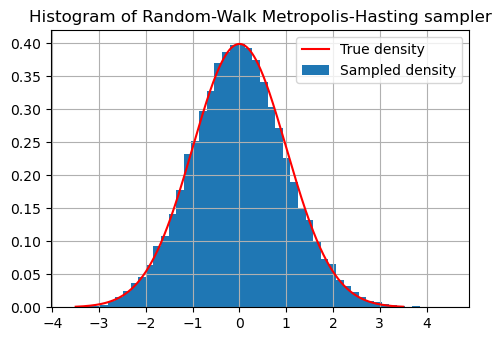

In [4]:
# Week 1, task 2
importlib.reload(samplers)
from samplers import random_walk_metropolis

theta0 = np.array([10])
step = 0.3
n_bins = 50
n_steps = 50000
rng = np.random.default_rng(1)
out = random_walk_metropolis(log_normal, theta0, step, n_steps, rng)
print("Mean:", out.mean())
print("Variance:", out.var())

x_space = np.linspace(-3.5,3.5,1000)
y_space = normal_dist(x_space)

plt.figure(figsize=(5.4,3.6))
plt.plot(x_space,y_space,color='red',label='True density')
plt.hist(out, bins=n_bins,density=True,label='Sampled density')
plt.grid(visible=True)
plt.title("Histogram of Random-Walk Metropolis-Hasting sampler")
plt.legend()
plt.show()

Since we can plot the true normal density (the red line), we can visually compare the histogram of the sample generated by the random-walk Metropolis-Hastings algorithm with the true density. We see that the histogram matches the normal density function, so the sampler gives a good chain of samples from the normal distribution.

In `amoc_model.py`, we code $V(y)$ and below we code this week's `log_prob` $= -2V(y)/\sigma^2$ function. Then we run the sampler on it, using $30,000$ iterations, step size $0.2$ and starting point $\theta_0 = y = 1.2$.

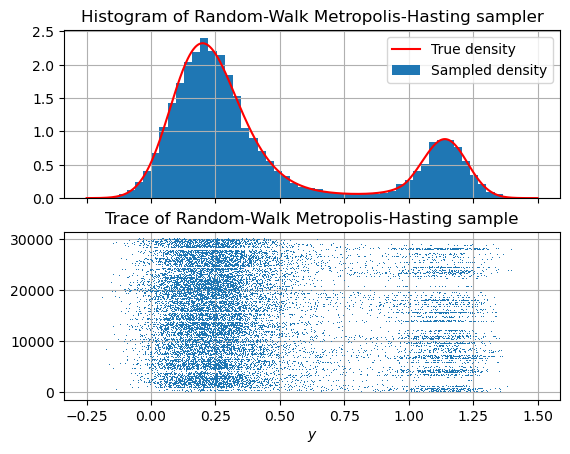

In [5]:
# Week 1, task 3 & 4
importlib.reload(samplers)
importlib.reload(amoc_model)
from samplers import random_walk_metropolis
from amoc_model import V

lambda_true = 0.16
a_true = 1.0
sigma_true = np.sqrt(0.02)

def log_prob(theta, l=lambda_true, a=a_true, sigma=sigma_true):
    return -2*np.sum(V(theta,l,a))/sigma**2

theta0 = np.array([1.2])
step = 0.2
n_steps = 30000
n_bins = 50
rng = np.random.default_rng(2)
sample = random_walk_metropolis(log_prob, theta0, step, n_steps, rng)

y_space = np.linspace(-0.25,1.5,1000)
pi_space = np.exp(-2*V(y_space,lambda_true,a_true)/sigma_true**2)
norm_const = np.trapz(pi_space,y_space)
norm_pi_space = pi_space / norm_const

fig, axs = plt.subplots(2,sharex=True)
axs[0].plot(y_space,norm_pi_space,color='red',label='True density')
axs[0].hist(sample, bins=n_bins,density=True,label='Sampled density')
axs[0].grid(visible=True)
axs[0].set_title("Histogram of Random-Walk Metropolis-Hasting sampler")
axs[0].legend()

x_space = np.linspace(0,n_steps,n_steps)
axs[1].plot(sample,x_space, ',')
axs[1].grid(visible=True)
axs[1].set_xlabel(r'$y$')
axs[1].set_title("Trace of Random-Walk Metropolis-Hasting sample")
plt.show()


As we can compare the histogram with the true density function, the performance of the sampler agrees closely with the true probability density.

Below, we compare the function $V(y)$ with the equilibria of $g(y)=0$, found earlier.

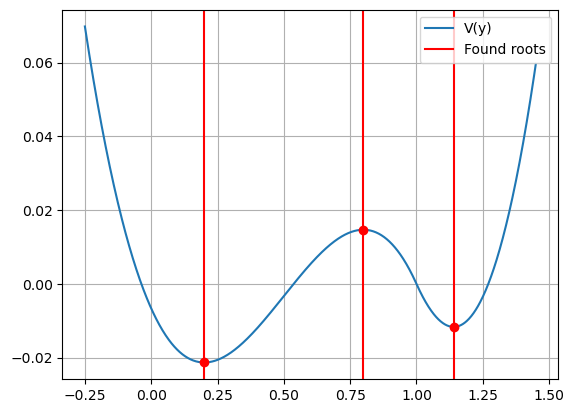

In [6]:
# week 1, question 1
x_vals = np.linspace(-0.25,1.45,1000)
V_vals = V(x_vals,lambda_true,a_true)
plt.plot(x_vals,V_vals)
for root in roots:
    plt.axvline(root,color='red')
    plt.plot(root,V(root,lambda_true,a_true),'ro')
plt.grid()
plt.legend(['V(y)','Found roots'])
plt.show()

$V(y)$'s critical-point structure matches the equilibria of $g(y)=0$. $V(y)$ has a local minimum at 0.2 and ~1.14 which correspond with the stable roots and a local maximum at 0.8 which corresponds with the unstable root. However, their depths are not equal as we can see in the plot.

To examine the relation between the step size and the acceptance rate, we run the sampler for several step sizes and compute the acceptance rate for each run. We do this for both the normal distribution and the target distribution $\pi(y)$.

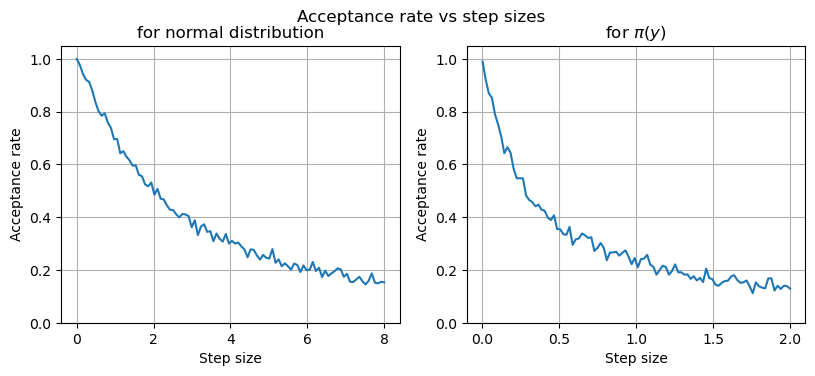

In [7]:
# week 1, question 2
importlib.reload(samplers)
from samplers import random_walk_metropolis, acceptance_rate

theta0 = np.array([1])
step_sizes = np.linspace(0.001,8,100)
n_steps = 1000
rng = np.random.default_rng(0)
acc_rates_rwmh_norm = []
for step in step_sizes:
    normal_sample_rwmh = random_walk_metropolis(log_normal, theta0, step, n_steps, rng)
    acc_rates_rwmh_norm.append(acceptance_rate(normal_sample_rwmh))

fig, axs = plt.subplots(1,2,figsize=(9.6,3.6))
fig.suptitle(r"Acceptance rate vs step sizes")
axs[0].plot(step_sizes,acc_rates_rwmh_norm)
axs[0].set_title(r"for normal distribution")

step_sizes2 = np.linspace(0.001,2,100)
n_steps = 1000
acc_rates_rwmh_Vy = []
for step in step_sizes2:
    V_sample_rwmh = random_walk_metropolis(log_prob, theta0, step, n_steps, rng)
    acc_rates_rwmh_Vy.append(acceptance_rate(V_sample_rwmh))

axs[1].plot(step_sizes2,acc_rates_rwmh_Vy)
axs[1].set_title(r"for $\pi(y)$")
for i in range(2):
    axs[i].grid(visible=True)
    axs[i].set_xlabel("Step size")
    axs[i].set_ylim(0,1.05)
    axs[i].set_ylabel("Acceptance rate")
plt.show()

As we can see in the plot, the larger the step size, the lower the acceptance rate. This is because with a small step size, it's harder to escape a well, but with a high step size, it's harder to make a step, since there is a higher probability that the proposed step is outside the area of the distribution. We see that, for example, `step_size` $= 0.001$ is clearly too small, but there is no hard boundary on useful step sizes. If we take acceptance rates between 0.8 and 0.2 as acceptable, then a step size between 1 and 6 would work for the normal distribution and step sizes between 0.1 and 1.3 for $\pi(y)$.

Now, we run two chains from different starting wells. We use starting values $\theta_0=1.2$ and $\theta_0=0.0$ and `step_size`$=0.2$ and `n_steps`$=50,000$. Below we plot their histograms and the true probability density function.

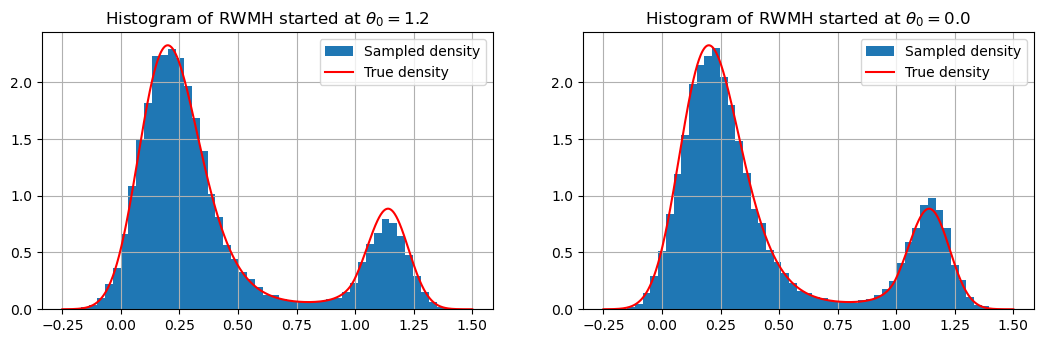

In [8]:
# Week 1, question 3
importlib.reload(samplers)
importlib.reload(amoc_model)
from samplers import random_walk_metropolis
from amoc_model import V

theta01 = np.array([1.2])
theta02 = np.array([0.0])
step = 0.2
n_steps = 50000
n_bins = 50
rng = np.random.default_rng(0)
sample1 = random_walk_metropolis(log_prob, theta01, step, n_steps, rng)
sample2 = random_walk_metropolis(log_prob, theta02, step, n_steps, rng)

y_space = np.linspace(-0.25,1.5,1000)
pi_space = np.exp(-2*V(y_space,lambda_true,a_true)/sigma_true**2)
norm_const = np.trapz(pi_space,y_space)
norm_pi_space = pi_space / norm_const

fig, axs = plt.subplots(1,2,sharex=True,figsize=(12.8,3.6))
axs[0].hist(sample1, bins=n_bins,density=True,label='Sampled density')
axs[0].set_title(rf"Histogram of RWMH started at $\theta_0=${theta01[0]}")
axs[1].hist(sample2, bins=n_bins,density=True,label='Sampled density')
axs[1].set_title(rf"Histogram of RWMH started at $\theta_0=${theta02[0]}")
for i in range(2):
    axs[i].plot(y_space,norm_pi_space,color='red',label='True density')
    axs[i].grid(visible=True)
    axs[i].legend()
plt.show()

As we can see, both historgrams generally agree with each other and with the true density. The histogram of the chain started at $1.2$ has slightly lower peak at the well around $1.14$ compared with the chain started at $0.0$. However, this is due to sampling noise rather than a property of the sampler, because it differs from seed to seed if this observation is present.

An important observation to make is that from a trace plot alone it's hard to see how well the random-walk follows the targeted distribution. It can look perfectly well-behaved and still sample from a wrong distribution. This means that you have to be careful in trusting a single chain's diagnostics. Therefore, we use histograms and compare them with the true probability density for now and we will introduce comparing measurements for this later.

## Week 2: Metropolis-adjusted Langevin algorithm

For this new algorithm we not only need a function `log_prob` as input, but also `grad_log_prob`. Since week 1's `log_prob` function was defined as `log_prob`$(\theta)= -2V(\theta)/\sigma^2$, we define `grad_log_prob` as `grad_log_prob`$(\theta) = -2$`grad_V`$(\theta)/\sigma^2$, where

$$\nabla V(y) = -\lambda +y\cdot|a-y|.$$

Here below, we check `grad_log_prob` against a central finite difference of $V$ and see that the two functions agree.

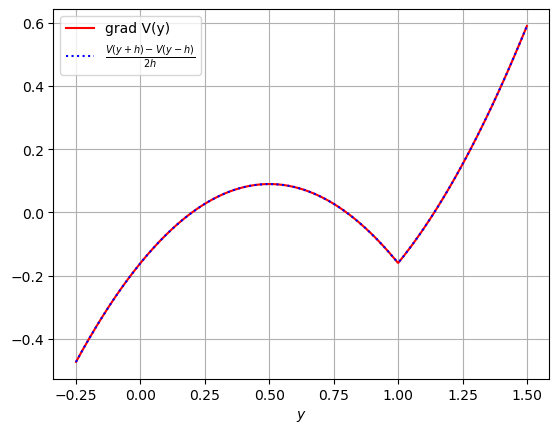

In [9]:
# Week 2, task 1
importlib.reload(amoc_model)
from amoc_model import grad_V

def grad_log_prob(theta,l=lambda_true, a=a_true, sigma=sigma_true):
    return -2*grad_V(theta,l,a)/sigma**2

h = 0.01
y1_space = np.linspace(-0.25,1.5,1000)
grad_V_space = grad_V(y1_space,lambda_true,a_true)
y_min_space = y1_space - h
y_plus_space = y1_space + h
diff_space = (V(y_plus_space,lambda_true,a_true)-V(y_min_space,lambda_true,a_true))/(2*h)

plt.plot(y1_space,grad_V_space,'r',label='grad V(y)')
plt.plot(y1_space,diff_space,'b:',label=r'$\frac{V(y+h)-V(y-h)}{2h}$')
plt.xlabel(r'$y$')
plt.grid(visible=True)
plt.legend()
plt.show()

In `samplers.py`, the function `mala` is defined. Here below we test this function on a standard normal distribution with $30,000$ iterations and starting point $\theta_0 = y = 10$.

Mean: 0.022053127336763942
Variance: 1.0265873584549616


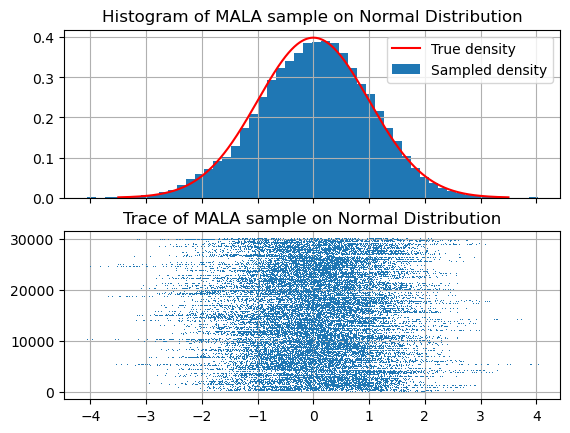

In [10]:
# Week 2, task 2
importlib.reload(samplers)
from samplers import mala

theta0 = np.array([10])
step = 0.3
n_bins = 50
n_steps = 30000
mean = []
variance = []
rng = np.random.default_rng(0)
normal_sample_mala = mala(log_normal, grad_log_normal, theta0, step, n_steps, rng)
print("Mean:", normal_sample_mala.mean())
print("Variance:", normal_sample_mala.var())

x_space = np.linspace(-3.5,3.5,1000)
y_space = normal_dist(x_space)

fig, axs = plt.subplots(2,sharex=True)
axs[0].plot(x_space,y_space,color='red',label='True density')
axs[0].hist(normal_sample_mala, bins=n_bins,density=True,label='Sampled density')
axs[0].grid(visible=True)
axs[0].set_title("Histogram of MALA sample on Normal Distribution")
axs[0].legend()

x_space_trace = np.linspace(0,n_steps,n_steps)
axs[1].plot(normal_sample_mala,x_space_trace, ',')
axs[1].grid(visible=True)
axs[1].set_title("Trace of MALA sample on Normal Distribution")
plt.show()

The histogram follows the true density very closely.

Then, we run `mala` on the same `log_prob` function as in week 1, but now with `grad_log_prob` also as input in the sampler. Below we use $\theta_0 = 1.5$, `step_size`$=0.2$ and `n_steps`$=30,000$.

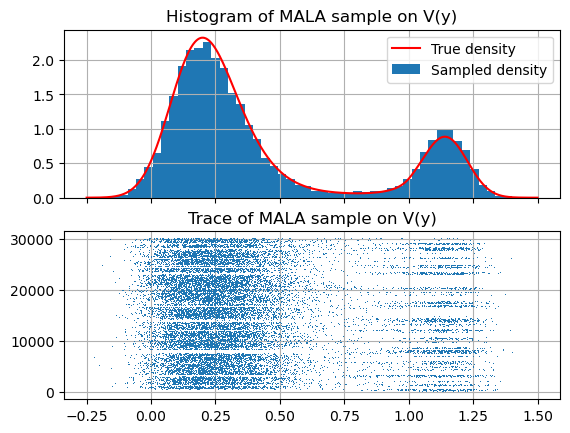

In [11]:
# week 2, task 3
importlib.reload(samplers)
importlib.reload(amoc_model)
from samplers import mala
from amoc_model import V

theta0 = np.array([1.5])
step = 0.2
n_bins = 50
n_steps = 30000
rng = np.random.default_rng(0)
sample_mala = mala(log_prob, grad_log_prob, theta0, step, n_steps, rng)

theta_space = np.linspace(-0.25,1.5,1000)
pi_space = np.exp(-2*V(theta_space,lambda_true,a_true)/sigma_true**2)
norm_const = np.trapz(pi_space,theta_space)
norm_pi_space = pi_space / norm_const

fig, axs = plt.subplots(2,sharex=True)
axs[0].plot(theta_space,norm_pi_space,color='red',label='True density')
axs[0].hist(sample_mala, bins=n_bins,density=True,label='Sampled density')
axs[0].grid(visible=True)
axs[0].set_title("Histogram of MALA sample on V(y)")
axs[0].legend()

x_space_trace = np.linspace(0,n_steps,n_steps)
axs[1].plot(sample_mala,x_space_trace, ',')
axs[1].grid(visible=True)
axs[1].set_title("Trace of MALA sample on V(y)")
plt.show()

We observe again that the histogram follows the true density function very closely, so for this starting value we have a well-performing sampler.

Below, we examine the relation between step size and acceptance rate for both the random-walk Metropolis-Hastings (RWMH) and Metropolis-adjusted Langevin algorithm (MALA) for the normal distribution and the density function $\pi(y)$. We compute the acceptance rate for a number of step sizes and startig value $\theta_0=y=1.0$ and $1,000$ iterations (to keep the runtime feasible).

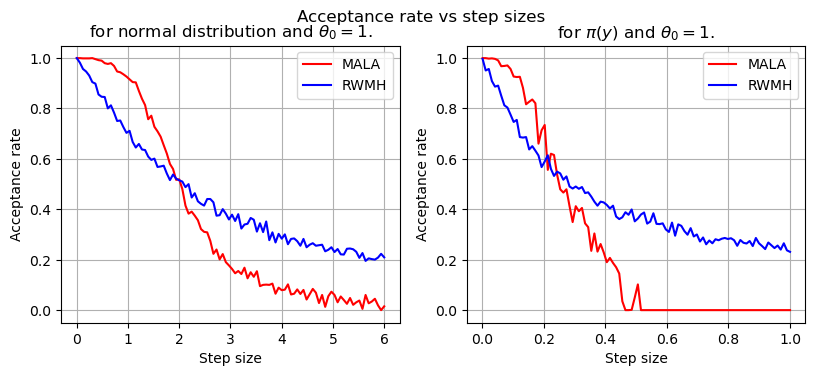

In [12]:
# week 2, question 1
importlib.reload(samplers)
from samplers import mala, random_walk_metropolis, acceptance_rate

theta0 = np.array([1])
step_sizes = np.linspace(0.001,6,100)
n_steps = 1000
rng = np.random.default_rng(0)
acc_rates_mala_norm = []
acc_rates_rwmh_norm = []
for step in step_sizes:
    normal_sample_mala = mala(log_normal, grad_log_normal, theta0, step, n_steps, rng)
    normal_sample_rwmh = random_walk_metropolis(log_normal, theta0, step, n_steps, rng)
    acc_rates_mala_norm.append(acceptance_rate(normal_sample_mala))
    acc_rates_rwmh_norm.append(acceptance_rate(normal_sample_rwmh))

fig, axs = plt.subplots(1,2,figsize=(9.6,3.6))
fig.suptitle(r"Acceptance rate vs step sizes")
axs[0].plot(step_sizes,acc_rates_mala_norm,'r-',label='MALA')
axs[0].plot(step_sizes,acc_rates_rwmh_norm,'b-',label='RWMH')
axs[0].set_title(rf"for normal distribution and $\theta_0 = {theta0[0]}$.")

step_sizes2 = np.linspace(0.001,1,100)
acc_rates_mala_Vy = []
acc_rates_rwmh_Vy = []
for step in step_sizes2:
    V_sample_mala = mala(log_prob, grad_log_prob, theta0, step, n_steps, rng)
    V_sample_rwmh = random_walk_metropolis(log_prob, theta0, step, n_steps, rng)
    acc_rates_mala_Vy.append(acceptance_rate(V_sample_mala))
    acc_rates_rwmh_Vy.append(acceptance_rate(V_sample_rwmh))

axs[1].plot(step_sizes2,acc_rates_mala_Vy,'r-',label='MALA')
axs[1].plot(step_sizes2,acc_rates_rwmh_Vy,'b-',label='RWMH')
axs[1].set_title(rf"for $\pi(y)$ and $\theta_0 = {theta0[0]}$.")

for i in range(2):
    axs[i].grid(visible=True)
    axs[i].set_xlabel("Step size")
    axs[i].set_ylabel("Acceptance rate")
    axs[i].legend()
plt.show()

As we can see in the plots above, for an acceptance rate > 0.5, MALA can use a larger step size than RWMH. However, for acceptance rates < 0.5, it is the other way around and RWMH can use a larger step size. The difference can be seen in the plots. Furthermore, in the plot for the $\pi(y)$ distribution, the acceptance rate of MALA is 0 for step sizes $>0.6$. This is because there is no convergence for these step sizes and the MALA-chain stays constant at the starting point.

To examine which method performs better when we choose the starting value far from the correct distribution, we plot below the histograms and traces from a chain using RWMH and a chain using MALA for starting point $\theta_0=10$ (step size $= 0.2$ and $10,000$ iterations).

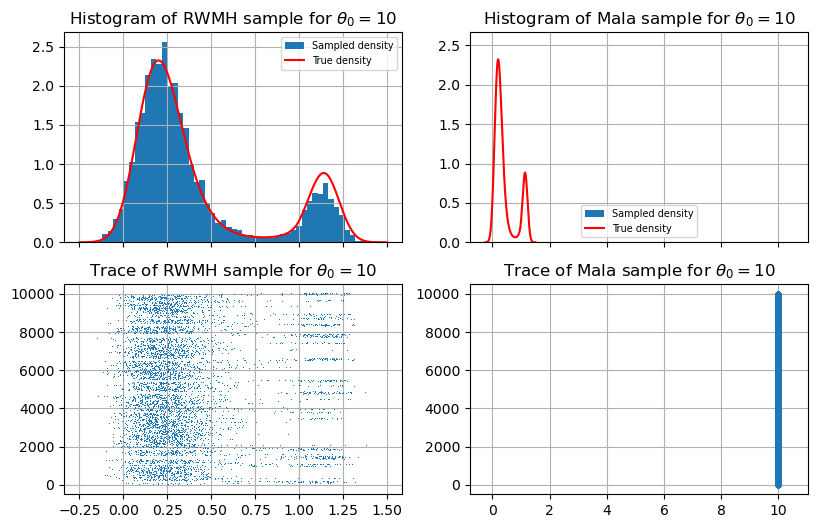

In [13]:
# week 2, question 2
importlib.reload(samplers)
from samplers import mala

theta0 = np.array([10])
step = 0.2
n_bins = 50
n_steps = 10000
rng = np.random.default_rng(0)
sample_mala = mala(log_prob, grad_log_prob, theta0, step, n_steps, rng)
sample_rwmh = random_walk_metropolis(log_prob, theta0, step, n_steps, rng)

theta_space = np.linspace(-0.25,1.5,1000)
pi_space = np.exp(-2*V(theta_space,lambda_true,a_true)/sigma_true**2)
norm_const = np.trapz(pi_space,theta_space)
norm_pi_space = pi_space / norm_const

x_space_trace = np.linspace(0,n_steps,n_steps)

fig,axs = plt.subplots(2,2,sharex='col',figsize=(9.6,6.0))
for i in range(2):
    if i == 0:
        sampler_name = 'RWMH'
        sample = sample_rwmh
    else:
        sampler_name = 'Mala'
        sample = sample_mala

    axs[0,i].hist(sample,bins=n_bins,density=True,label='Sampled density')
    axs[0,i].set_title(rf"Histogram of {sampler_name} sample for $\theta_0 = {theta0[0]}$")
    axs[0,i].plot(theta_space,norm_pi_space,color='red',label='True density')
    axs[0,i].grid(visible=True)
    axs[0,i].legend(fontsize=7)

    axs[1,i].set_title(rf"Trace of {sampler_name} sample for $\theta_0 = {theta0[0]}$")
    axs[1,i].grid(visible=True)
axs[1,0].plot(sample_rwmh,x_space_trace, ',')
axs[1,1].plot(sample_mala,x_space_trace, '.')
axs[0,1].set_ylim(0,8/3)
plt.show()

We see that RWMH performs better than MALA. In fact, MALA doesn't converge to the correct density at all and stays at starting point $\theta_0=10$, while RWMH does give histogram that matches the true density. This is because far away from both wells, the gradient is very large (either in positive or in negative direction) and that leads to "overshooting" the proposal step. As a consequence, the proposal never gets accepted and the chain stays at the starting value.

Including the gradient in the sampler does not give a better performance with regards to crossing between different wells. This is because if the walk is close to the barrier between the two wells, then the gradient is close to zero (close to an extreme point of `log_prob`). In this situation, the drift term based on `grad_log_prob` in MALA is close to zero and therefore the proposal step is largely based on the noise term, but this doesn't differ a lot from RWMH where the step is only based on the noise term.

## Week 3: Hamiltonian Monte Carlo

We start with building the function `y_eq` in `amoc_model.py`, based on the `root_finder` function from week 1. The `y_eq` function performs `root_finder` for starting value $y_0=1.15$, which is close to the largest root at $(\lambda_{true},a_{true})$, and then checks whether the found root $y$ is stable.

Since we can also compute the largest root by hand for this problem, we can check whether this function gives the correct root. The function `y_eq_direct` computes the four possible roots $$y_{1,2} = \frac{a \pm \sqrt{a^2 - 4\lambda}}{2} \quad\text{ if } y\leq a, \qquad y_{3,4} = \frac{a \pm \sqrt{a^2 + 4\lambda}}{2} \quad\text{ if } y> a$$ and outputs the largest of $y_1,y_2$ if $y \leq a$ or the largest of $y_3,y_4$ if $y>a$.

Below, we compare the output of `y_eq` with the output of `y_eq_direct` on a grid of $(\lambda,a) \in [0,0.5] \times [0.6,1.2]$. This corresponds to three times the standard deviation above and below the mean of the prior distribution of $\lambda$ and $a$. Furthermore, $\lambda$ is capped at $\lambda \geq 0$ (since $\lambda<0$ would not be a realistic value in this model).

In [48]:
# week 3, task 1 check against closed form
importlib.reload(amoc_model)
from amoc_model import y_eq, y_eq_direct

lambda_test_space = np.linspace(0.0,0.5,50)
a_test_space = np.linspace(0.6,1.2,50)
L,A = np.meshgrid(lambda_test_space,a_test_space)
newton_error = 0
error = 0
total = 0
for row in range(L.shape[0]):
    for col in range(L.shape[1]):
        direct_output = y_eq_direct(L[row,col],A[row,col])
        try:
            y_eq_output = y_eq(L[row,col],A[row,col])
            if np.abs(y_eq_output - direct_output) > 1e-5:
                error += 1
        except:
            newton_error += 1
        total += 1
print(f'Error rate (difference between Newtons method and direct computation): {(error/total)*100:.2f}%')
print(f'Newton error rate (Newtons method fails to give a root): {(newton_error/total)*100:.2f}%')

Error rate (difference between Newtons method and direct computation): 0.00%
Newton error rate (Newtons method fails to give a root): 6.68%


As we can see, there is no instance of $(\lambda,a)$ where `y_eq` gives a different answer than `y_eq_direct`. This indicates that the found roots using Newton's method are correct. However, there are some instances where Newton's method does not output a root at all. Closer examination reveals that this happens if $a>1.14 = y_{true}$. If we would only check for $a\in [0.6,1.14]$, then Newton's method always gives a root (and agrees with the root found from direct computation).

Below, we check the runtimes of both functions and we see that the function `y_eq` based on Newton's method has a faster runtime than the direct computation. Therefore, we use `y_eq` in the following tasks.

In [15]:
# Week 3, task 1 compare runtimes
importlib.reload(amoc_model)
from amoc_model import y_eq, y_eq_direct
import time

t0 = time.time()
y_true = y_eq(lambda_true,a_true)
t1 = time.time()
y_testtrue = y_eq_direct(lambda_true,a_true)
t2 = time.time()

print(f"Time  y_eq: {(t1-t0)*1000:.3f} ms")
print(f"Time y_eq2: {(t2-t1)*1000:.3f} ms")

Time  y_eq: 0.050 ms
Time y_eq2: 0.073 ms


Now, we generate 5 "noisy measurements" based on the true value $y_{true} = y_{eq}(\lambda_{true},a_{true})$ by sampling $y_{obs,i} \sim \mathcal{N}(y_{true},\sigma_{obs}^2)$ for $i =1,\dots,5$, where $\sigma_{obs}^2 = 0.02$.

In [16]:
# Week 3, task 2
importlib.reload(amoc_model)
from amoc_model import y_eq

rng = np.random.default_rng(0)
lambda_true = 0.16
a_true = 1.0
sigma_obs = 0.02

y_true = y_eq(lambda_true,a_true)
print(f'y_true = {y_true}')
y_obs_list = []
for _ in range(5):
    y_obs = y_true + sigma_obs * rng.normal()
    y_obs_list.append(y_obs)
print(f'y_obs_list = {y_obs_list}')

y_true = 1.140312423743285
y_obs_list = [1.1428270281651527, 1.1376703264774588, 1.1531208767521506, 1.1424104260863457, 1.1295990362800628]


In `samplers.py` we built the function `hmc` and here below we test it on the 2 dimensional normal distribution with $\mu=(0,0)$ and $\sigma^2 = (1,1)$. We also check whether `random_walk_metropolis` and `mala` also work on this 2-dimensional distribution.

Mean var 1: 0.012170138908549493
Mean var 2: -0.0048387426963924975
Variance var 1: 1.0124231484142923
Variance var 2: 0.9899434296408853


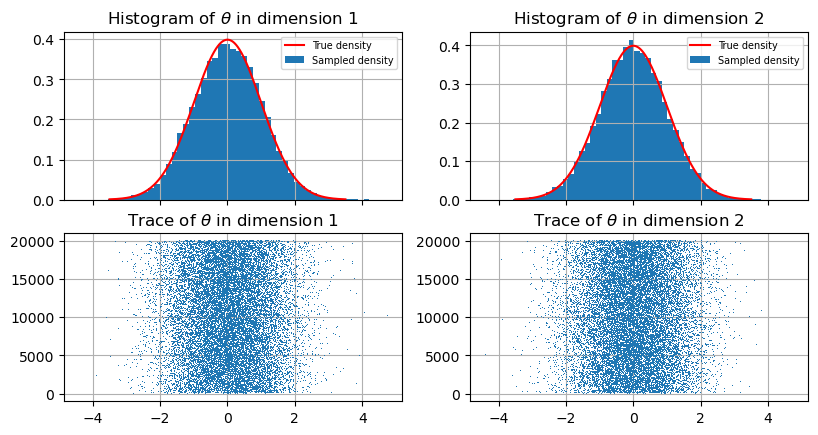

In [17]:
# Week 3, task 4 & 5
importlib.reload(samplers)
from samplers import random_walk_metropolis, mala, hmc

theta0 = np.array([5,1])
eps = 0.1
L = 15
n_bins = 50
n_steps = 20000
mean = []
variance = []
rng = np.random.default_rng(0)
normal_sample_hmc = hmc(log_normal_2D, grad_log_normal_2D, theta0, eps, L, n_steps, rng)
normal_sample_mala = mala(log_normal_2D, grad_log_normal_2D, theta0, eps, n_steps, rng)
normal_sample_rwmh = random_walk_metropolis(log_normal_2D, theta0, eps, n_steps, rng)
sample = normal_sample_hmc
print("Mean var 1:", normal_sample_hmc[:,0].mean())
print("Mean var 2:", normal_sample_hmc[:,1].mean())
print("Variance var 1:", normal_sample_hmc[:,0].var())
print("Variance var 2:", normal_sample_hmc[:,1].var())

x_space = np.linspace(-3.5,3.5,1000)
y0_space = normal_dist(x_space)
x_space_trace = np.linspace(0,n_steps,n_steps)

fig, axs = plt.subplots(2,2,sharex=True,figsize=(9.6,4.8))
for i in range(2):
    axs[0,i].plot(x_space,y0_space,color='red',label='True density')
    axs[0,i].hist(normal_sample_hmc[:,i], bins=n_bins,density=True,label='Sampled density')
    axs[0,i].set_title(rf"Histogram of $\theta$ in dimension {i+1}")
    axs[0,i].grid(visible=True)
    axs[0,i].legend(fontsize=7)

    axs[1,i].plot(normal_sample_hmc[:,i],x_space_trace, ',')
    axs[1,i].set_title(rf"Trace of $\theta$ in dimension {i+1}")
    axs[1,i].grid(visible=True)
plt.show()

As we can see, the histogram of both dimensions agree with the normal distribution. Thus, the function `hmc` performs correct on a standard normal distribution.

Below we define this week's functions `log_prob_2D` and `grad_log_prob_2D`. 
In the previous exercises we sampled $\theta=y$, but now we turn the problem around and try to sample the model parameters $\lambda$ and $a$. Therefore, we now have $\theta=(\lambda,a)$ and we want to have `log_prob_2D`$=\log(\pi(\theta|y))$. By Bayes' Theorem (without the evidence factor), we know that 
\begin{align*}
    \log\big(\pi(\theta|y)\big) &= \log\big(\pi(y|\theta)\big) +\log\big(\pi_0(\theta)\big),
    \pi(\theta|y) &= \pi(y|\theta)\cdot \pi_0(\theta)\\
\end{align*}
where $\pi(y|\theta)$ is the likelihood and $\pi_0(\theta)$ is the prior distribution.

As prior distributions, we use $\lambda \sim \mathcal{N}(0.2, 0.1^2)$ and $a \sim \mathcal{N}(1.0, 0.5^2)$, which is coded in the function `log_normal_2D` with $\mu=(0.2,1.0)$ and $\sigma^2=(0.1^2,0.5^2)$. For the likelihood, we use the 5 observations $\{y_{obs,i}\}_{i=1}^5$ of $y$, so in this case $\pi(y|\theta) = \prod^5_{i=1}\pi(y_i|\theta)$, which is computed by evaluating the probability of $y_{obs,i}$ under $\mathcal{N}(y_{eq}(\lambda,a),\sigma^2)$ for each $y_i$ and taking the sum.

For `grad_log_prob_2D`, observe that
\begin{equation*}
    \nabla\log\big(\pi(\theta|y)\big) = \sum^5_{i=1}\nabla\log(\pi(y_i|\theta)) + \nabla\log(\pi_0(\theta)).
\end{equation*}
The gradient of the log-prior is just the gradient of the 2D normal distribution, encoded in `grad_log_normal_2D`, and the gradient for the likelihood is the sum of the gradient of the normal distribution multiplied by the gradient of the function `y_eq` for each $y_i$. We encoded the gradient of `y_eq` in the function `grad_y_eq` using central finite differences, i.e. we used
$$\frac{\partial y_{eq}}{\partial \lambda}(\lambda,a) = \frac{y_{eq}(\lambda+h,a)-y_{eq}(\lambda-h,a)}{2\cdot h} \qquad \frac{\partial y}{\partial a}(\lambda,a) = \frac{y_{eq}(\lambda,a+h)-y_{eq}(\lambda,a-h)}{2\cdot h}$$
for very small $h$.

In [18]:
# week 3, task 3
importlib.reload(amoc_model)
from amoc_model import grad_y_eq, y_eq

l_mu = 0.2
l_sigma = 0.1
a_mu = 1.0
a_sigma = 0.5

def log_prob_2D(theta,y_list=y_obs_list,sigma=sigma_obs):
    l = theta[0]
    a = theta[1]
    try:
        y_root = y_eq(l,a)
    except:
        #if Newton's method did not find a root y for lambda and a, then log_prob outputs -infty
        return -np.inf
    likelihood = np.sum(log_normal(y_list,mu=y_root,sigma=sigma))
    return likelihood + log_normal_2D(theta,mu=[l_mu,a_mu],sigma=[l_sigma,a_sigma])

def grad_log_prob_2D(theta, y_list=y_obs_list,sigma=sigma_obs):
    l = theta[0]
    a = theta[1]
    try:
        y_root = y_eq(l,a)
    except:
        #if Newton's method did not find a root y for lambda and a, then grad_log_prob outputs [0,0]
        return np.array([0,0])
    likelihood = np.sum(grad_log_normal(y_list,mu=y_root,sigma=sigma))
    try:
        dy_eq_dl, dy_eq_da = grad_y_eq(l,a)
    except:
        return np.array([0,0])
    dlog_prob_dl = (likelihood * -dy_eq_dl) + grad_log_normal(l,mu=l_mu,sigma=l_sigma)
    dlog_prob_da = (likelihood * -dy_eq_da) + grad_log_normal(a,mu=a_mu,sigma=a_sigma)
    return np.array([dlog_prob_dl, dlog_prob_da])

After defining these functions, we check how this posterior distribution looks like. We make a surface plot of the posterior $\pi((\lambda,a)|y)$ on a 2-dimensional plane $(\lambda,a)$ and two plots of the marginal posterior for $\lambda$ and for $a$. We compute this by summing over all values of $a$ to obtain the value of the marginal posterior for a certain $\lambda$ and vice versa for the marginal posterior of $a$.

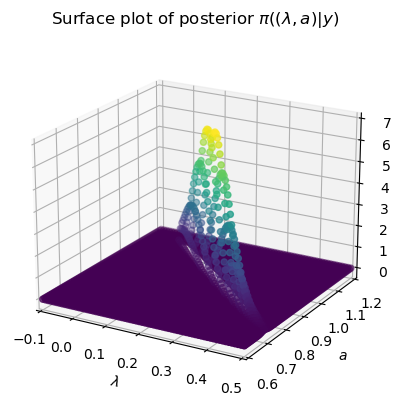

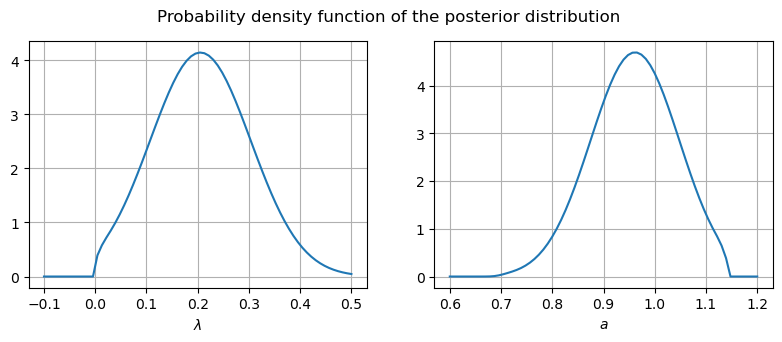

In [19]:
#check how log_prob looks like

lambda_space = np.linspace(-0.1,0.5,70)
a_space = np.linspace(0.6,1.2,70)
L,A = np.meshgrid(lambda_space,a_space)
prob_space = np.empty_like(L)
for row in range(L.shape[0]):
    for col in range(L.shape[1]):
        theta = [L[row,col],A[row,col]]
        prob_space[row,col] = np.exp(log_prob_2D(theta))
ax = plt.figure().add_subplot(projection='3d')
ax.scatter(L,A,prob_space,c=prob_space)
ax.view_init(elev=20., azim=-60, roll=0)
ax.set_xlim(-0.1, 0.5)
ax.set_ylim(0.6, 1.2)
ax.set_xlabel(r'$\lambda$')
ax.set_ylabel(r'$a$')
ax.set_zlabel(r'$\pi(\lambda,a)$')
ax.set_title(r'Surface plot of posterior $\pi((\lambda,a)|y)$')
plt.show()

probL_space = []
for col in range(L.shape[1]):
    probL_space.append(np.sum(prob_space[:,col]))
norm_const_L = np.trapz(probL_space,lambda_space)
probL_space = np.array(probL_space) / norm_const_L

probA_space = []
for row in range(L.shape[0]):
    probA_space.append(np.sum(prob_space[row,:]))
norm_const_A = np.trapz(probA_space,a_space)
probA_space = np.array(probA_space) / norm_const_A

fig, axs = plt.subplots(1,2,figsize=(9.6,3.2))
fig.suptitle('Probability density function of the posterior distribution')
axs[0].plot(lambda_space,probL_space)
axs[0].grid(visible=True)
axs[0].set_xlabel(r'$\lambda$')

axs[1].plot(a_space,probA_space)
axs[1].grid(visible=True)
axs[1].set_xlabel(r'$a$')
plt.show()

As we can see the area with high probability is a small linear shape on the $(\lambda,a)$-plane. The second plot shows the marginal posterior distributions for $\lambda$ and $a$, which indicates that the probability density among this linear shape is not uniform, but there is a peak around $(\lambda,a)= (0.2,0.95)$. We can use these distributions to validate the samples of the different samplers.

To check if the gradient function `grad_log_prob_2D` is defined as intended, we compare it with the central finite differences of the function `log_prob_2D`. Here below we tested this for four different values of $\theta$, we see that both functions agree to at least four digits.

In [20]:
#week 3, question 1
def finite_diff_log_prob(theta):
    h = 0.001
    l = theta[0]
    a = theta[1]
    d_dl = (log_prob_2D([l+h,a])-log_prob_2D([l-h,a]))/(2*h)
    d_da = (log_prob_2D([l,a+h])-log_prob_2D([l,a-h]))/(2*h)
    return np.array([d_dl, d_da])

list_theta = [np.array([0.2,0.8]), np.array([0.2,1.8]), np.array([0.6,0.2]), np.array([0.1,1.0])]
for test_theta in list_theta:
    grad_test = grad_log_prob_2D(test_theta)
    diff_test = finite_diff_log_prob(test_theta)
    print(f"Gradient at {test_theta} according to grad_log_prob_2D  :", grad_test)
    print(f"Gradient at {test_theta} according to finite differences:", diff_test)
    print('')

Gradient at [0.2 0.8] according to grad_log_prob_2D  : [1470.19953119 1470.84635228]
Gradient at [0.2 0.8] according to finite differences: [1470.0651414  1470.85637627]

Gradient at [0.2 1.8] according to grad_log_prob_2D  : [-4750.50272197 -9052.72722599]
Gradient at [0.2 1.8] according to finite differences: [-4750.4443252  -9052.73789106]

Gradient at [0.6 0.2] according to grad_log_prob_2D  : [2041.4740291  1836.96478463]
Gradient at [0.6 0.2] according to finite differences: [2041.4068988  1836.96782795]

Gradient at [0.1 1. ] according to grad_log_prob_2D  : [533.17811029 571.04443924]
Gradient at [0.1 1. ] according to finite differences: [533.13162252 571.04638547]



Now, we run all three samplers on this week's functions with `step_size`$=0.01$, starting point $\theta=(0.2,1.0)$ and 20,000 iterations for RWMH and MALA and 2,000 for HMC.

In [21]:
# Week 3, task 6
importlib.reload(samplers)
from samplers import random_walk_metropolis, mala, hmc
import time

theta0 = np.array([0.2,1.0])
eps = 0.01
L = 15
n_bins = 50
n_steps = 20000
n_steps_hmc = 2000
rng = np.random.default_rng(0)
t0 = time.time()
sample_hmc = hmc(log_prob_2D, grad_log_prob_2D, theta0, eps, L, n_steps_hmc, rng)
t1 = time.time()
sample_mala = mala(log_prob_2D, grad_log_prob_2D, theta0, eps, n_steps, rng)
t2 = time.time()
sample_rwmh = random_walk_metropolis(log_prob_2D, theta0, eps, n_steps, rng)
t3 = time.time()

print(f"Runtime for RWMH: {t3 - t2:.3f} sec --> {(n_steps/(t3 - t2)):.1f} samples per sec")
print(f"Runtime for MALA: {t2 - t1:.3f} sec --> {(n_steps/(t2 - t1)):.1f} samples per sec")
print(f"Runtime for  HMC: {t1 - t0:.3f} sec --> {(n_steps_hmc/(t1 - t0)):.1f} samples per sec")

Runtime for RWMH: 1.349 sec --> 14824.9 samples per sec
Runtime for MALA: 3.515 sec --> 5690.2 samples per sec
Runtime for  HMC: 4.374 sec --> 457.3 samples per sec


We see that HMC has the longest runtime compared to RWMH and MALA, even though it produced a ten times smaller chain (2,000 versus 20,000 samples). Computing the number of samples per second makes the comparison fairer and then HMC is even more expensive than RWMH and MALA. This is due to the number of gradient evalutions, which is the most expensive part of the computations of the different methods. Each HMC iteration computes $L=15$ gradients (in each leapfrog step one and $L$ leapfrog steps per iteration), while MALA uses $1$ gradient evaluation per iteration and RWMH does not use the gradient at all. This explains why RWMH computes the most samples per second, then MALA and then HMC. However, this does not answer whether this higher cost of HMC is worth it. We come back to this question later in this notebook.

We make a scatter plot for these three chains, one for each sampler.

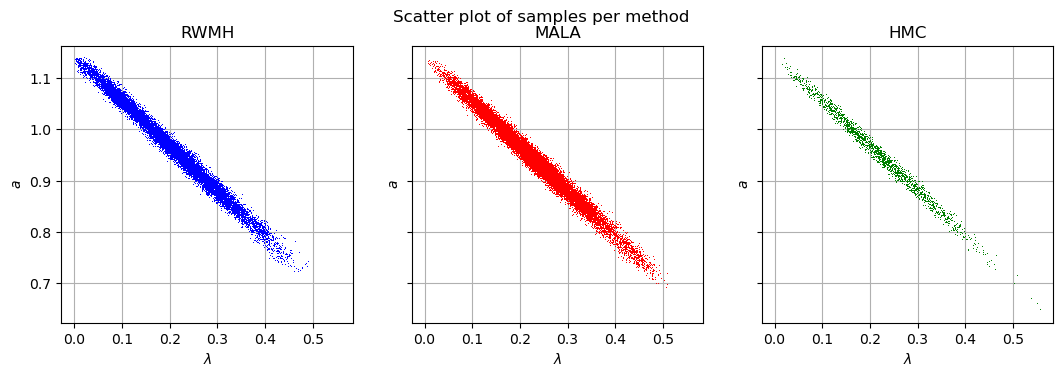

In [22]:
# week 3, question 2
fig,axs = plt.subplots(1,3,sharex=True,sharey=True,figsize=(12.8,3.6))
fig.suptitle('Scatter plot of samples per method')
for i in range(3):
    axs[i].set_xlabel(r'$\lambda$')
    axs[i].set_ylabel(r'$a$')
    axs[i].grid(True)
axs[0].plot(sample_rwmh[:,0],sample_rwmh[:,1],'b,')
axs[0].set_title('RWMH')
axs[1].plot(sample_mala[:,0],sample_mala[:,1],'r,')
axs[1].set_title('MALA')
axs[2].plot(sample_hmc[:,0],sample_hmc[:,1],'g,')
axs[2].set_title('HMC')
plt.show()

We see a linear shape, which suggests that there is a linear relation between $\lambda$ and $a$.

If we go back to the equilibrium condition $$\lambda = |a-y|y,$$ then for a fixed value of $y$ this is indeed a linear equation (with a kink because of the absolute value signs). For the samples we generated, we used 5 observations of $y$ around the value of $y_{true} := y_{eq}(\lambda_{true},a_{true})\approx 1.14$. 
Since the values of $a$ range from 0.6 to 1.1, we can safely assume $a<y_{true}$, which makes the equilibrium condition $$\lambda = (y_{true}-a)*y_{true}.$$
This yields
$$ a = -\frac{1}{y_{true}}\lambda +y_{true}.$$
We added this line to the scatter plots in the graph below and then we see that this line corresponds with the samples, so this linear equation explains the shape of the samples.

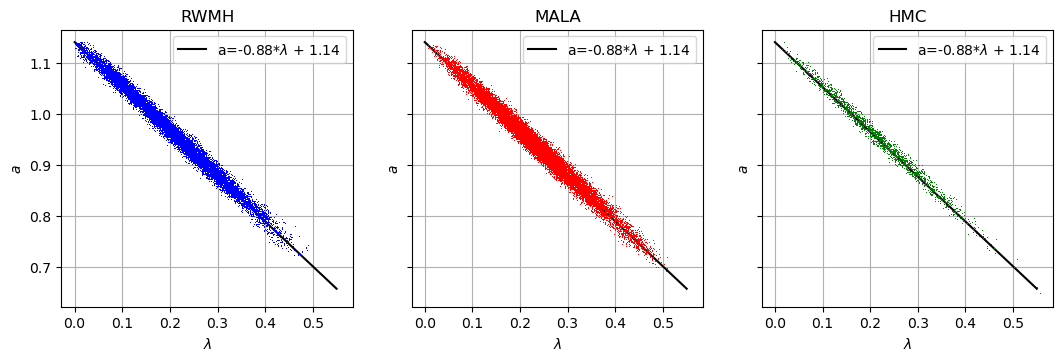

In [23]:
# week 3, question 3
y_guess = 1.14
a = -1/y_guess
b = y_guess
def f(x,a,b):
    return a*x+b

lambda_lin_space = np.linspace(0,0.55,2)
a_lin_space = f(lambda_lin_space,a,b)

fig,axs = plt.subplots(1,3,sharex=True,sharey=True,figsize=(12.8,3.6))
for i in range(3):
    axs[i].plot(lambda_lin_space,a_lin_space,'black',label=rf'a={a:.2f}*$\lambda$ + {b:.2f}')
    axs[i].set_xlabel(r'$\lambda$')
    axs[i].set_ylabel(r'$a$')
    #axs[i].set_xlim(-0.2,1.5)
    #axs[i].set_ylim(0,1.2)
    axs[i].legend()
    axs[i].grid(True)
axs[0].plot(sample_rwmh[:,0],sample_rwmh[:,1],'b,')
axs[0].set_title('RWMH')
axs[1].plot(sample_mala[:,0],sample_mala[:,1],'r,')
axs[1].set_title('MALA')
axs[2].plot(sample_hmc[:,0],sample_hmc[:,1],'g,')
axs[2].set_title('HMC')
plt.show()

In the three panels we see the same long, tilted ridge, but the HMC panel contains far fewer points than the other two. This is because we chose the number of samples for HMC to be $2,000$ while RWMH and MALA computed $20,000$ samples. Although HMC has far fewer points, this does not need to imply that the HMC chain contains less information. We will come back to this later.

Below we plot a histogram and a trace plot for $\lambda$ and $a$ for all three methods. We also included the probability density function that we computed directly from `log_prob_2D` (this is the red line in the graphs). All figures are based on a chain of $2,000$ samples to make a fair comparison.

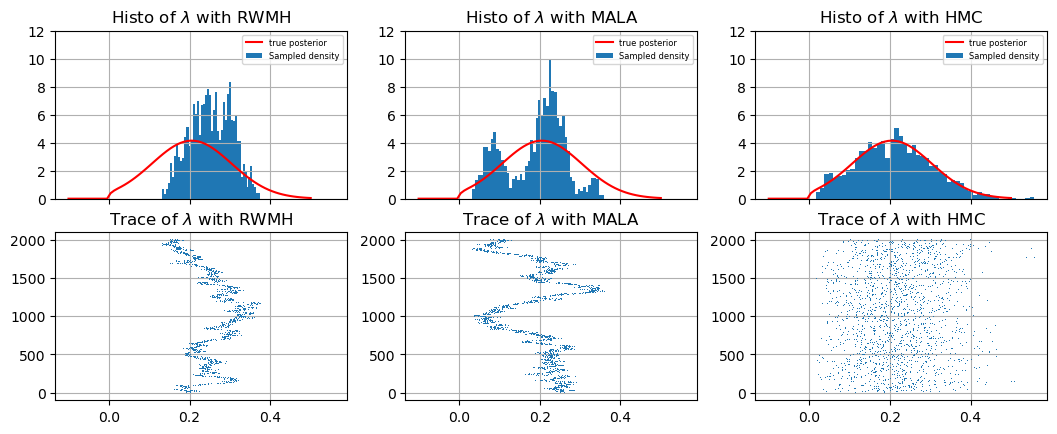

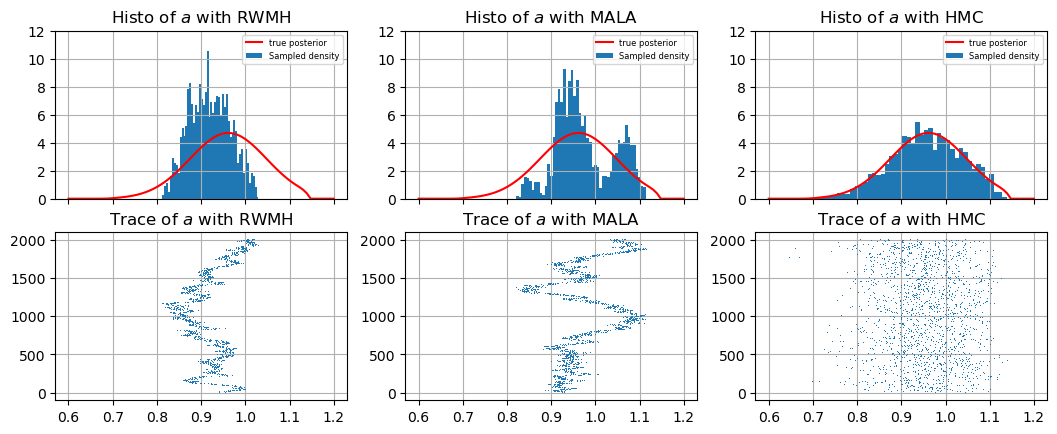

In [24]:
# week 3, question 4
n_steps_hmc = 2000
x_space_trace_hmc = np.linspace(0,n_steps_hmc,n_steps_hmc)

for i in range(2):
    fig, axs = plt.subplots(2,3,sharex=True,figsize=(12.8,4.8))
    for j in range(3):
        if j == 0:
            sample = sample_rwmh
            alg_name = 'RWMH'
        if j == 1:
            sample = sample_mala
            alg_name = 'MALA'
        if j == 2:
            sample = sample_hmc
            alg_name = 'HMC'

        if i == 0:
            axs[0,j].set_title(rf"Histo of $\lambda$ with {alg_name}")
            axs[1,j].set_title(rf"Trace of $\lambda$ with {alg_name}")
            axs[0,j].plot(lambda_space,probL_space,color='red',label="true posterior")
        if i == 1:
            axs[0,j].set_title(rf"Histo of $a$ with {alg_name}")
            axs[1,j].set_title(rf"Trace of $a$ with {alg_name}")
            axs[0,j].plot(a_space,probA_space,color='red',label="true posterior")

        axs[0,j].hist(sample[-n_steps_hmc:,i], bins=n_bins,density=True,label='Sampled density')
        axs[1,j].plot(sample[-n_steps_hmc:,i],x_space_trace_hmc, ',')
        axs[0,j].set_ylim(0,12)
        axs[0,j].grid(visible=True)
        axs[1,j].grid(visible=True)
        axs[0,j].legend(fontsize=6)
    plt.show()

These histograms and traces reveal that the subsequent samples in the chains from RWMH and MALA are very close to the previous sample, while the samples generated by HMC make bigger jumps. In other words, subsequent samples in the chains from RWMH and MALA are much more correlated than in the HMC chain. This leads to a better posterior distribution, since the histogram of the HMC chain agrees quite closely with the probability density function in contrast to the histograms of RWMH and MALA. This shows that the number of samples in a chain does not tell the whole story, the quality of the samples is also an important factor to consider. To assess this, we will introduce two measures.

## Week 4: Diagnostics and efficiency

A single chain that looks converged may actually only be exploring a limited area of the probability distribution. For example, above we saw that the samples of RWMH and MALA are on a long, narrow ellipse, but the histograms show that they do not have the correct distribution regarding $\lambda$ and $a$. (Q5)

This poses an important question: when does a chain have the correct probability distribution? If the true distribution is known, the answer is simple and we can simply compare it, but in general we do not know the true distribution (in fact, this is often what we want to find out). Therefore, we need another way to measure this, which can be done with the r-hat value. To compute this value we generate several chains of samples with each chain having a different starting point. If all chains sample from the correct distribution, then their distributions are similar to each other and the variance between different chains is similar to the variance within each chain. This is exactly what r-hat quantifies. If the variance between different chains is close to the variance within the chains, then r-hat is close to 1, which indicates that the chains end up with the same probability distributions despite having different starting points. However this does not prove that this probability distribution is the true one.If all chains stay in the same wrong area, then r-hat is also close to one. However, we can reduce this risk by taking spread-out starting points.

Another important question is how much information the samples contain? As we saw in the plots above, the RWMH and MALA chains contained more samples, but subsequent samples were more correlated than in the HMC chain. Therefore, the distribution of the HMC chain followed the correct distribution more closely with fewer samples. To quantify this, we compute the effective sample size (ESS), which quantifies how much information the samples contain. If $n$ samples are correlated, then they contain less information than $n$ independent drawn samples. The effective sample size of a chain is the number of independent samples that would contain as much information as the chain itself. 

In `samplers.py` we wrote the functions `r_hat` and `effective_sample_size`. Below we test `r_hat` on 4 chains of independent samples and we test `effective_sample_size` on one chain of independent samples, to check if they are implemented correctly.

In [25]:
# Week 4, task 3
importlib.reload(samplers)
from samplers import r_hat, effective_sample_size

rng = np.random.default_rng(1)
n_chains = 4
n_samples = 10000
n_dim = 2
indep_chains = rng.normal(size=(n_chains,n_samples,n_dim))

rhat = r_hat(indep_chains)
print(f'r_hat = {rhat}')

indep_sample = rng.normal(size=(n_samples))
ESS = effective_sample_size(indep_sample)
print(f'ESS = {ESS}')

r_hat = [0.99997931 0.99999688]
ESS = 10000.0


We obtain values $\hat{r} \approx 1$ and $ESS \approx n$, where $n$ is the number of samples used (in this run 10,000). This indicates that the four chains sample from the same distribution and that one chain contains the same information as $\sim n$ independent samples (which is obvious since the chain consists of independent samples). These are values we expect from independent normal draws, so the functions `r_hat` and `effective_sample_size` are implemented correctly.

We run 4 chains per method for different starting values. We use the values $(\lambda,a) = (0.1,0.7), (0.1,1.05), (0.5,1.05), (0.5,0.7)$, which are spread out across the $(\lambda,a)$-space. Note that $(0.1,1.05)$ and $(0.5,0.7)$ are on the linear shape that we observed before, while $(0.1,0.7)$ and $(0.5,1.05)$ are outside this area. We use step size $0.01$ for all methods and $20,000$ samples per chain for RWMH and MALA. For HMC, we use $2,000$ samples and $L=15$ leapfrog steps.

In [40]:
# Week 4, task 2
importlib.reload(samplers)
from samplers import random_walk_metropolis, mala, hmc
import time

step = 0.01
L = 15
n_steps = 20000
n_steps_hmc = 2000
rng = np.random.default_rng(0)

starting_point = [np.array([0.1,0.7]),np.array([0.1,1.05]),np.array([0.5,1.05]),np.array([0.5,0.7])]
n_chains = len(starting_point)

chains_rwmh = np.zeros((n_chains,n_steps,starting_point[0].size))
chains_mala = np.zeros((n_chains,n_steps,starting_point[0].size))
chains_hmc = np.zeros((n_chains,n_steps_hmc,starting_point[0].size))
time_rwmh = 0
time_mala = 0
time_hmc = 0
for i in range(n_chains):
    t0 = time.time()
    chains_rwmh[i] = random_walk_metropolis(log_prob_2D, starting_point[i], step, n_steps, rng)
    t1 = time.time()
    chains_mala[i] = mala(log_prob_2D, grad_log_prob_2D, starting_point[i], step, n_steps, rng)
    t2 = time.time()
    chains_hmc[i] = hmc(log_prob_2D, grad_log_prob_2D, starting_point[i], step, L, n_steps_hmc, rng)
    t3 = time.time()
    time_rwmh += t1-t0
    time_mala += t2-t1
    time_hmc += t3-t2
print(f'Time to compute chains using RWMH: {time_rwmh:.2f} sec')
print(f'Time to compute chains using MALA: {time_mala:.2f} sec')
print(f'Time to compute chains using  HMC: {time_hmc:.2f} sec')

Time to compute chains using RWMH: 4.93 sec
Time to compute chains using MALA: 20.15 sec
Time to compute chains using  HMC: 12.92 sec


Using these chains, we compute the $\hat{r}$ values for all three methods and we plot the traces of the 4 chains per method.

r_hat for RWMH = [1.04055048 1.03986082]
r_hat for MALA = [1.01505262 1.01508233]
r_hat for  HMC = [2.71374841 2.73003321]


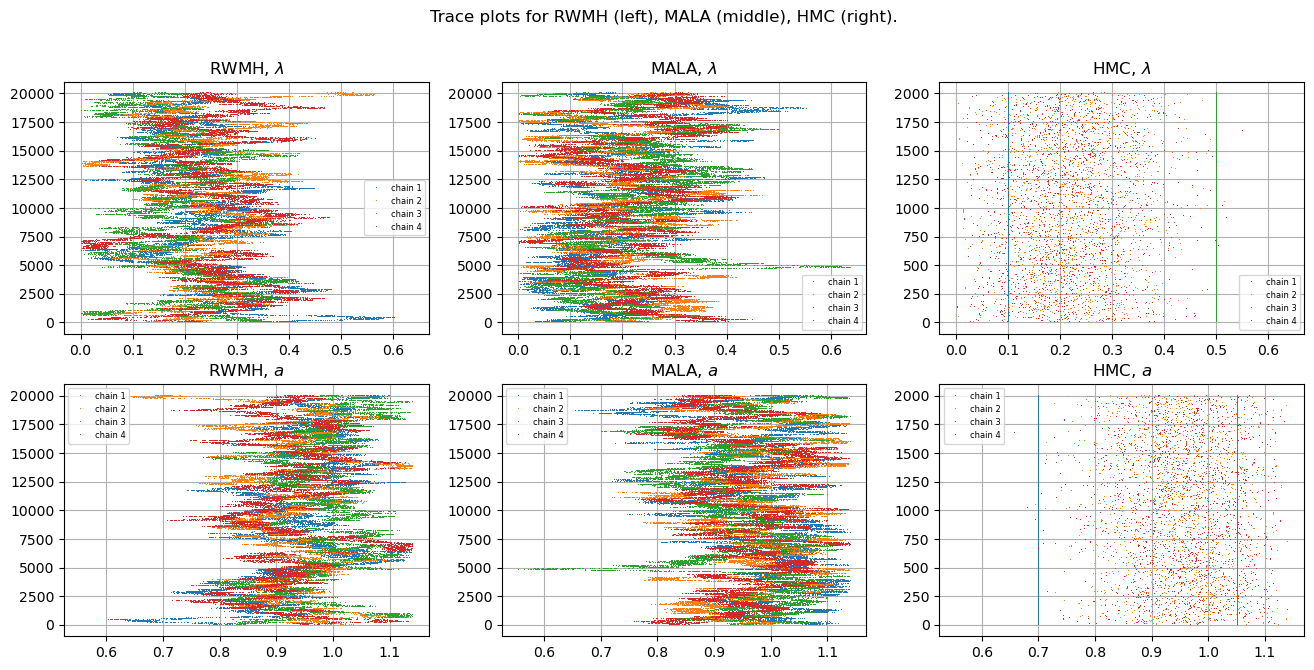

In [41]:
# week 4, question 1
importlib.reload(samplers)
from samplers import r_hat

r_hat_rwmh = r_hat(chains_rwmh)
r_hat_mala = r_hat(chains_mala)
r_hat_hmc = r_hat(chains_hmc)
print(f'r_hat for RWMH = {r_hat_rwmh}')
print(f'r_hat for MALA = {r_hat_mala}')
print(f'r_hat for  HMC = {r_hat_hmc}')

fig,axs = plt.subplots(2,3,sharex='row',figsize=(16.0,7.2))
fig.suptitle(f'Trace plots for RWMH (left), MALA (middle), HMC (right).')
x_space_trace = np.linspace(0,n_steps,n_steps)
x_space_trace_hmc = np.linspace(0,n_steps_hmc,n_steps_hmc)
for j in range(len(starting_point[0])):
    for i in range(3):
        if i == 0:
            method = 'RWMH'
            chains = chains_rwmh
            space_trace = x_space_trace
        if i == 1:
            method = 'MALA'
            chains = chains_mala
            space_trace = x_space_trace
        if i == 2:
            method = 'HMC'
            chains = chains_hmc
            space_trace = x_space_trace_hmc
        for k in range(n_chains):
            axs[j,i].plot(chains[k,:,j],space_trace,',',label=f'chain {k+1}')
        axs[j,i].grid(True)
        axs[j,i].legend(fontsize=6)
        if j == 0:
            variable = '\lambda'
        if j == 1:
            variable = 'a'
        axs[j,i].set_title(f'{method}, ${variable}$')
plt.show()

We get R-hat values for RWMH and MALA $\hat{r} \leq 1.03$, which indicate that the four chains with different starting values yield samples from the same probability distribution. The trace plots confirm this, because for RWMH and MALA we see all four colors (from the four chains) mixed in the same area.

For HMC, however, we get $\hat{r} = 2.72$ for both $\lambda$ and $a$. This indicates that the chains do not have the same distribution. It is easy to see that two of the four chains stay constant, i.e. their acceptance rate is 0.0%. Let us take a closer look at the energy errors, by examining the median energy error (the average in this case is not defined, since the energy error is $-\infty$ for some iterations).

In [42]:
# week 4, question 2
rng = np.random.default_rng(0)

for i in range(n_chains):
    chain = hmc(log_prob_2D, grad_log_prob_2D, starting_point[i], step, L, n_steps_hmc, rng, show_energy_error=True)
    print(f'Acceptance rate is: {acceptance_rate(chain)*100:.2f}%')
    theta0 = starting_point[i]
    print(f'Gradient of log posterior at {theta0} is {grad_log_prob_2D(theta0)}')
    print('')

The median energy error is: -673.1506795886977
Acceptance rate is: 0.00%
Gradient of log posterior at [0.1 0.7] is [4243.46202026 3478.91545805]

The median energy error is: -0.012124222114971772
Acceptance rate is: 87.10%
Gradient of log posterior at [0.1  1.05] is [43.07416558 37.43102659]

The median energy error is: -170.06019324583673
Acceptance rate is: 0.00%
Gradient of log posterior at [0.5  1.05] is [-1907.60434936 -2639.47536565]

The median energy error is: -0.012488457606103509
Acceptance rate is: 86.80%
Gradient of log posterior at [0.5 0.7] is [-13.05646444  20.4977433 ]



If we examine the medians (see above), then we observe that they are very negative for the two chains which are constant, while the medians for the two other chains are close to zero (which is needed to have a non-negligible probability to accept a proposed step). We see that the size of the gradient of the log posterior at the starting points $(0.1,0.7)$ and $(0.5,1.05)$ is very large, either in positive or negative direction. This means that the proposed next step shoots very far away from the starting point, which leads to a high energy error, which leads to a negligible chance of being accepted as next step.

To fix this, we choose a smaller value for step size $\varepsilon$ (and a larger value for $L$ to keep the trajectory length roughly fixed). This leads to more leapfrog steps, which decrease the gradient used to compute the proposal. As a consequence, the proposed point is closer to the starting point and there is a lower energy error and a higher probability that the point will be accepted.

In [43]:
# week 4, question 3
importlib.reload(samplers)
from samplers import hmc, r_hat
import time

new_L = 90
new_eps = 0.0015
rng = np.random.default_rng(0)

chains_hmc2 = np.zeros((n_chains,n_steps_hmc,starting_point[0].size))
time_hmc2 = 0
for i in range(n_chains):
    t0 = time.time()
    chains_hmc2[i] = hmc(log_prob_2D, grad_log_prob_2D, starting_point[i], new_eps, new_L, n_steps_hmc, rng, show_energy_error=True)
    t1 = time.time()
    time_hmc2 += t1 - t0
    print(f'Acceptance rate is: {acceptance_rate(chains_hmc2[i])*100:.2f}%')

r_hat_hmc = r_hat(chains_hmc2)
print(f'r_hat for  HMC = {r_hat_hmc}')
print(f'Time to compute chains using  HMC: {time_hmc2:.2f} sec')

The median energy error is: -5.3929921159934224e-05
Acceptance rate is: 96.90%
The median energy error is: -3.784518667515613e-05
Acceptance rate is: 97.40%
The median energy error is: -3.466624819736808e-05
Acceptance rate is: 97.80%
The median energy error is: -3.7677725284623875e-05
Acceptance rate is: 96.20%
r_hat for  HMC = [1.00035565 1.00036774]
Time to compute chains using  HMC: 90.41 sec


It turns out that for $\varepsilon = 0.0015$, the median energy errors for each chain are close to zero, the acceptance rate is above 80% and the value of $\hat{r}$ is below $1.03$ (in fact, it is very close to 1, much better than we saw before for RWMH and MALA). However, this comes with a higher runtime.

To confirm that the chains now agree on the same posterior, we plot the trace for $\lambda$ and $a$ below.

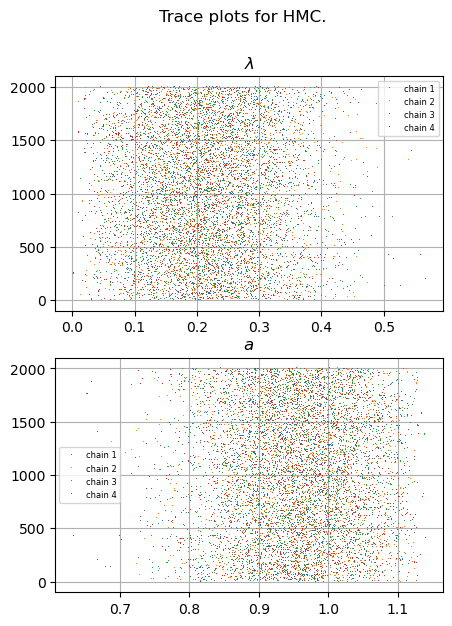

In [44]:
# week 4, question 3 confirmation
fig,axs = plt.subplots(2,1,figsize=(5,6.7))
fig.suptitle(f'Trace plots for HMC.')
for j in range(2):
    for k in range(n_chains):
        axs[j].plot(chains_hmc2[k,:,j],x_space_trace_hmc,',',label=f'chain {k+1}')
    axs[j].grid(True)
    axs[j].legend(fontsize=6)
    if j == 0:
        variable = '\lambda'
    if j == 1:
        variable = 'a'
    axs[j].set_title(f'${variable}$')
plt.show()

We see that the colors of the four chains are well mixed, which indicate that they sample from the same distribution.

Now with every chain converged, we compare the effective sample size (ESS) for all three methods. This tells us how much information each chain gives us about the posterior. However, with the new value of $\varepsilon$ (and $L$) for HMC, the runtime for HMC is significantly longer than for the other methods. To make a fair comparison, we also compute the ESS per second.

In [45]:
#week 4, question 4
importlib.reload(samplers)
from samplers import effective_sample_size

ess_rwmh_l = []
ess_mala_l = []
ess_hmc_l = []
ess_rwmh_a = []
ess_mala_a = []
ess_hmc_a = []
for i in range(n_chains):
    ess_rwmh_l.append(effective_sample_size(chains_rwmh[i,:,0]))
    ess_rwmh_a.append(effective_sample_size(chains_rwmh[i,:,1]))
    ess_mala_l.append(effective_sample_size(chains_mala[i,:,0]))
    ess_mala_a.append(effective_sample_size(chains_mala[i,:,1]))
    ess_hmc_l.append(effective_sample_size(chains_hmc2[i,:,0]))
    ess_hmc_a.append(effective_sample_size(chains_hmc2[i,:,1]))

print('-------------------------------------------------')
print('| Method, parameter | Average ESS | ESS per sec |')
print('-------------------------------------------------')
print(f"| RWMH, lambda      | {np.mean(ess_rwmh_l):11.3f} | {np.mean(ess_rwmh_l)/(time_rwmh/4):11.3f} |")
print(f"| RWMH, a           | {np.mean(ess_rwmh_a):11.3f} | {np.mean(ess_rwmh_a)/(time_rwmh/4):11.3f} |")
print(f"| MALA, lambda      | {np.mean(ess_mala_l):11.3f} | {np.mean(ess_mala_l)/(time_mala/4):11.3f} |")
print(f"| MALA, a           | {np.mean(ess_mala_a):11.3f} | {np.mean(ess_mala_a)/(time_mala/4):11.3f} |")
print(f"| HMC,  lambda      | {np.mean(ess_hmc_l):11.3f} | {np.mean(ess_hmc_l)/(time_hmc2/4):11.3f} |")
print(f"| HMC,  a           | {np.mean(ess_hmc_a):11.3f} | {np.mean(ess_hmc_a)/(time_hmc2/4):11.3f} |")
print('-------------------------------------------------')

-------------------------------------------------
| Method, parameter | Average ESS | ESS per sec |
-------------------------------------------------
| RWMH, lambda      |      24.400 |      19.815 |
| RWMH, a           |      24.531 |      19.921 |
| MALA, lambda      |      31.216 |       6.198 |
| MALA, a           |      31.289 |       6.213 |
| HMC,  lambda      |     635.236 |      28.103 |
| HMC,  a           |     635.689 |      28.124 |
-------------------------------------------------


Above we computed the mean of the ESS and the mean of the ESS per second of the four chains for each method and parameter.
We see that the ESS of the HMC chains is significantly higher than the RWMH and MALA chains. If we look at the ESS per second score than HMC is still the best performing sampler, however the difference with RWMH and MALA is much less significant due to the high runtime of HMC.

An important observation to make is that the choice of $L\cdot \varepsilon$ for HMC influences this ESS per second. Increasing $L$ even further than we did leads to an even higher score of ESS per second, which we omit in this notebook to keep the runtime feasible. Furthermore, the lower value for $\varepsilon$ is only necessary in the first phase of the chain to move away from the starting point. If we would modify HMC to have this lower $\varepsilon$ for the first iterations and then switch to the original $\varepsilon$, then we could obtain both a low runtime and a high ESS score, which would increase the ESS per second score significantly. 

# Conclusion

Our goal in the second part of this notebook was to sample from the posterior distribution of $\theta=(\lambda,a)$, based on some noisy observations of $y$ and to compare the performance of the three samplers in doing this. We chose starting values for $(\lambda,a)$ spread-out across the $\theta$-space to generate 4 separate chains of samples to compute the r-hat value for RWMH, MALA and HMC. We found r-hat values of ~$1.03$ for RWMH and ~$1.015$ for MALA. For HMC, we observed that two of the four chains did not converge, because the gradient at the starting point was too steep. To fix this, we used a smaller value of $\varepsilon$ in HMC (and a larger value of $L$ to keep the trajectory length roughly fixed). With these new parameters, all chains did converge and these chains yielded a r-hat value of ~$1.0004$, which is significantly better than the other two samplers produced. 

We also assessed the effective sample sizes that the three samplers produce in each chain. On average, the effective sample size (ESS) of a chain produced by RWMH was ~$25$, while MALA chains had an effective sample size of ~$31$. For the HMC sampler using the adjusted values of $\varepsilon$ and $L$, the effective sample size was ~$635$, a clear distinction to the other two samplers. Even if we account for the higher runtime that HMC had, it still had the highest ESS per second score of all three methods: ~$28$ for HMC versus ~$20$ for RWMH and ~$6$ for MALA (the exact numbers depend from run to run).

Given these results, we conclude that HMC is the best performing sampler of the three. Chains with different starting values sample from the same distribution with HMC and each chain contains more information than chains produced by RWMH or MALA. To illustrate this conclusion, we plotted the histograms and traces for each chain produced by the three samplers and compare it to the true distribution of the posterior.

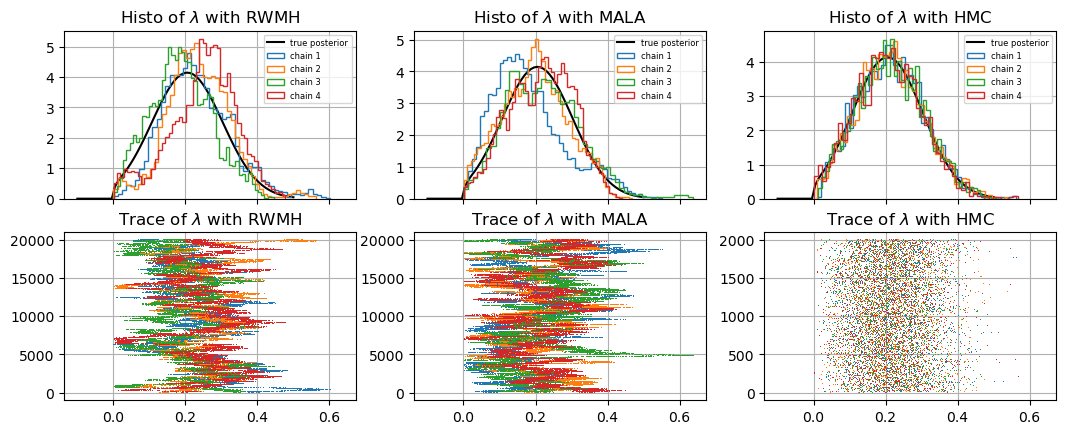

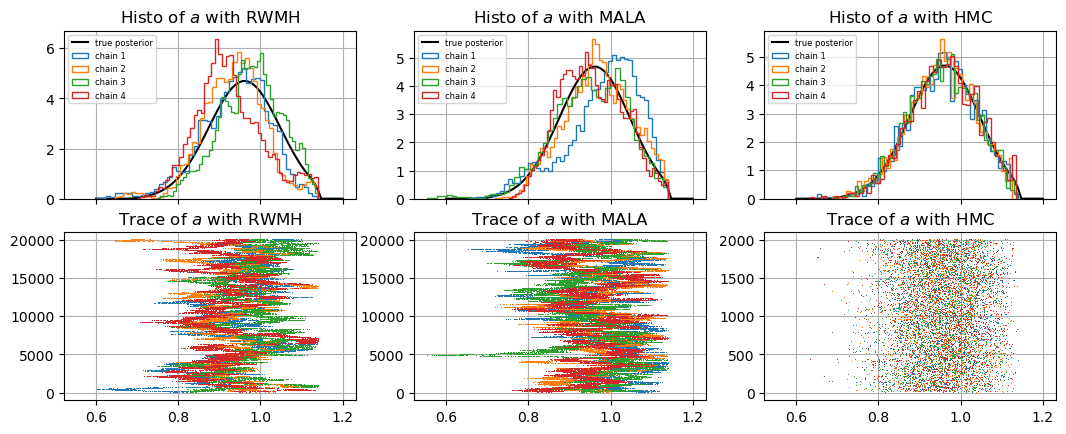

In [46]:
n_steps_hmc = 2000
n_steps = 20000
x_space_trace = np.linspace(0,n_steps,n_steps)
x_space_trace_hmc = np.linspace(0,n_steps_hmc,n_steps_hmc)

for i in range(2):
    fig, axs = plt.subplots(2,3,sharex=True,figsize=(12.8,4.8))
    for j in range(3):
        if j == 0:
            chains = chains_rwmh
            alg_name = 'RWMH'
            x_space = x_space_trace
        if j == 1:
            chains = chains_mala
            alg_name = 'MALA'
            x_space = x_space_trace
        if j == 2:
            chains = chains_hmc2
            alg_name = 'HMC'
            x_space = x_space_trace_hmc
        if i == 0:
            var_name = '$\lambda$'
            axs[0,j].plot(lambda_space,probL_space,color='black',label="true posterior")
        if i == 1:
            var_name = '$a$'
            axs[0,j].plot(a_space,probA_space,color='black',label="true posterior")
        for k in range(n_chains):
            axs[0,j].hist(chains[k,:,i], bins=n_bins,density=True,label=f'chain {k+1}',histtype='step')
            axs[1,j].plot(chains[k,:,i],x_space, ',')

        axs[0,j].set_title(rf"Histo of {var_name} with {alg_name}")
        axs[1,j].set_title(rf"Trace of {var_name} with {alg_name}")
        axs[0,j].grid(visible=True)
        axs[1,j].grid(visible=True)
        axs[0,j].legend(fontsize=6)
    plt.show()

We observe that the histograms of the different chains generated by RWMH and MALA differ more from each other than those generated by HMC. Furthermore, the HMC histograms match the target distribution more closely. The traces of the HMC chains also exhibit larger jumps across the $\lambda$- and $a$-spaces than those of RWMH and MALA, which suggests that subsequent samples are less correlated and thus contain more information. This corresponds with the higher ESS values for HMC chains. Note that each chain of RWMH and MALA contains $20,000$ samples, whereas each HMC chain contains only $2,000$ samples.

An important remark to this results, however, is that these results hold only for appropriately chosen values of $\varepsilon$ and $L$. Furthermore, we tested these samplers on only one target distribution and the ESS per second score depends on the specific computational setup.